# 09 · Do sinal bruto ao OEE: historiador + SQL

**Objetivo:** ver o caminho completo de um KPI industrial: a máquina publica **mudanças de estado** e **contadores**, um historiador guarda tudo numa tabela, e o SQL transforma linhas em **OEE**.

* Um turno de 8 h (06:00 às 14:00, almoço de 30 min às 10:00) é reproduzido em poucos segundos via MQTT, com os horários reais do turno.
* O historiador usa uma tabela **estreita** `(tag, ts, value)`, o formato que quase todo historiador usa por baixo.

In [1]:
# Configuração: deixa a raiz do repositório no caminho de import
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from common.notebook import load, run_in_background, require_broker
require_broker()
import sqlite3, json, time
import pandas as pd
h = load("09-historian-and-oee/historian_oee.py")

broker MQTT encontrado em localhost:1883


## 1. O que a máquina publica

In [2]:
eventos = h.simulate_shift()
estados = [(ts.strftime("%H:%M"), v["state"], v["reason"]) for tag, ts, v in eventos if tag == "state"]
print(f"{len(eventos)} eventos no turno; {len(estados)} mudanças de estado:")
pd.DataFrame(estados, columns=["hora", "estado", "motivo"])

772 eventos no turno; 18 mudanças de estado:


,hora,estado,motivo
0,06:00,RUNNING,
1,06:35,DOWN,jam
2,06:55,RUNNING,
3,07:26,DOWN,material shortage
4,07:31,RUNNING,
5,08:08,DOWN,jam
6,08:12,RUNNING,
7,08:56,DOWN,jam
8,09:08,RUNNING,
9,10:00,PLANNED_STOP,lunch


Repare: a máquina **não publica "estou rodando" a cada segundo**. Publica só a mudança (report by exception) e um contador acumulado por minuto. É o historiador que reconstrói a linha do tempo.

## 2. Gravando no historiador

In [3]:
db = sqlite3.connect(":memory:", check_same_thread=False, isolation_level=None)
sub = h.historian(db); time.sleep(0.3)
h.replay(eventos)
sub.loop_stop(); sub.disconnect()
print("amostras gravadas:", db.execute("SELECT COUNT(*) FROM samples").fetchone()[0], "de", len(eventos), "publicadas")
pd.read_sql("SELECT * FROM samples ORDER BY ts LIMIT 8", db)

amostras gravadas: 772 de 772 publicadas


,tag,ts,value
0,state,2026-11-12T06:00:00+00:00,"{""state"": ""RUNNING"", ""reason"": """"}"
1,count/good,2026-11-12T06:01:00+00:00,47
2,count/reject,2026-11-12T06:01:00+00:00,0
3,count/good,2026-11-12T06:02:00+00:00,90
4,count/reject,2026-11-12T06:02:00+00:00,0
5,count/good,2026-11-12T06:03:00+00:00,132
6,count/reject,2026-11-12T06:03:00+00:00,1
7,count/good,2026-11-12T06:04:00+00:00,174


Uma única tabela guarda tudo: estados (como JSON) e contadores (como número). Para historiadores de verdade (TimescaleDB, InfluxDB, PI) a ideia é a mesma, com compressão e índices por tempo.

## 3. Tempo em cada estado (função de janela `LEAD`)

Cada mudança de estado dura até a próxima. `LEAD(ts)` pega o horário da linha seguinte; a diferença é a duração.

In [4]:
duracoes = pd.read_sql(h.STATE_DURATIONS, db)
duracoes["minutos"] = (duracoes["seconds"] / 60).round(1)
duracoes[["state", "reason", "minutos", "events"]]

,state,reason,minutos,events
0,RUNNING,,377.0,10
1,DOWN,jam,36.0,3
2,DOWN,electrical fault,32.0,2
3,PLANNED_STOP,lunch,30.0,1
4,DOWN,material shortage,5.0,1


## 4. Pareto de paradas

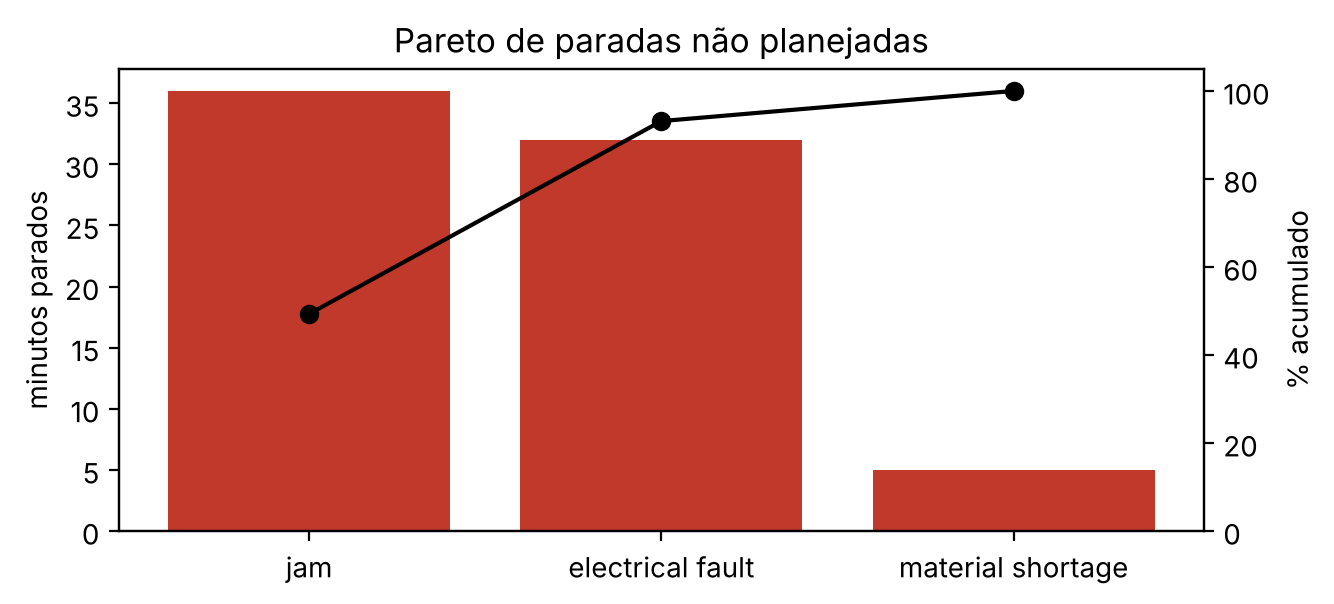

In [5]:
import matplotlib.pyplot as plt
down = duracoes[duracoes.state == "DOWN"].sort_values("minutos", ascending=False)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(down.reason, down.minutos, color="#c0392b")
ax2 = ax.twinx(); ax2.plot(down.reason, down.minutos.cumsum() / down.minutos.sum() * 100, color="k", marker="o")
ax2.set_ylim(0, 105); ax2.set_ylabel("% acumulado"); ax.set_ylabel("minutos parados"); ax.set_title("Pareto de paradas não planejadas")
plt.show()

O Pareto diz **onde atacar primeiro**: os motivos à esquerda somam a maior parte do tempo perdido.

## 5. Peças por hora (função de janela `LAG`)

O contador é acumulado, então a produção de cada minuto é `valor - valor anterior`.

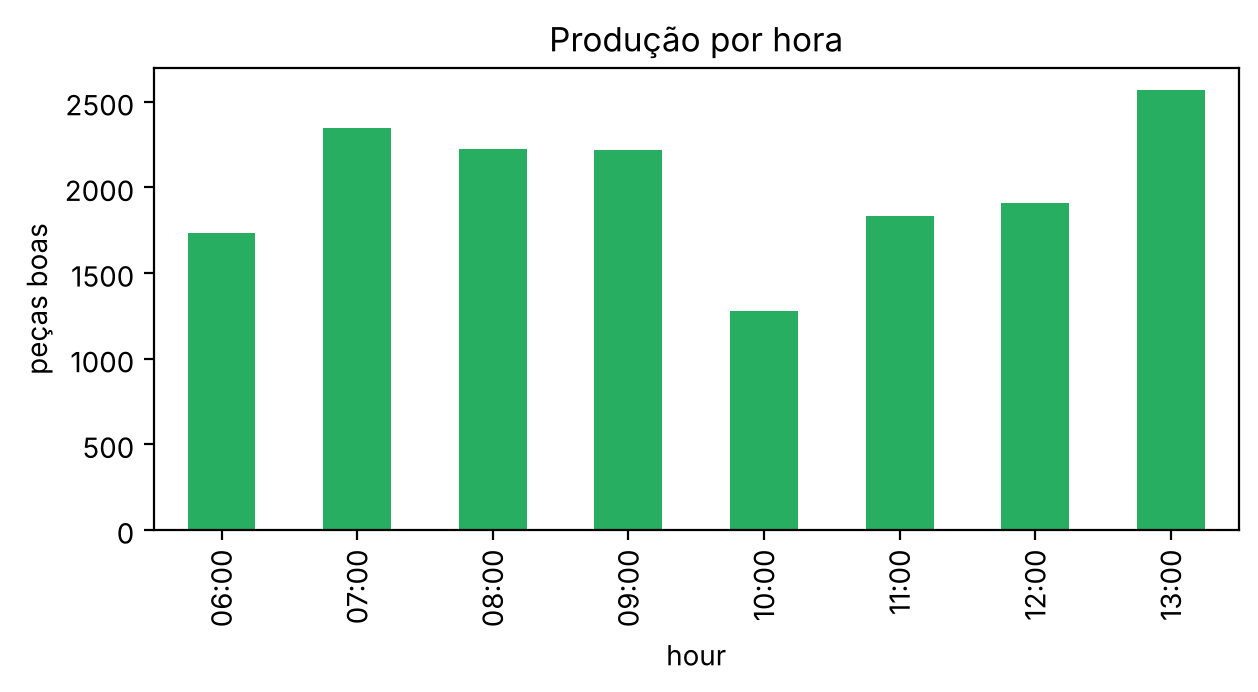

,hour,good_parts
0,06:00,1737
1,07:00,2346
2,08:00,2224
3,09:00,2220
4,10:00,1280
5,11:00,1832
6,12:00,1907
7,13:00,2569


In [6]:
por_hora = pd.read_sql(h.PARTS_PER_HOUR, db)
ax = por_hora.plot.bar(x="hour", y="good_parts", legend=False, figsize=(7, 3), color="#27ae60")
ax.set_ylabel("peças boas"); ax.set_title("Produção por hora"); plt.show()
por_hora

A hora das 10:00 tem menos peças por causa do almoço planejado. Horas com quedas sem explicação são onde estão as paradas do Pareto.

## 6. O OEE

In [7]:
k = h.oee(db)
print(f"Tempo planejado : {k['planned_s']/3600:.2f} h  (8 h de turno menos 30 min de almoço)")
print(f"Tempo rodando   : {k['run_s']/3600:.2f} h")
print(f"Peças           : {k['good']} boas + {k['reject']} refugo")
print()
print(f"Disponibilidade = rodando / planejado                 = {k['availability']:.1%}")
print(f"Performance     = peças x ciclo ideal ({h.IDEAL_CYCLE_S}s) / rodando = {k['performance']:.1%}")
print(f"Qualidade       = boas / total                         = {k['quality']:.1%}")
print(f"OEE             = D x P x Q                            = {k['oee']:.1%}")

Tempo planejado : 7.50 h  (8 h de turno menos 30 min de almoço)
Tempo rodando   : 6.28 h
Peças           : 16115 boas + 228 refugo

Disponibilidade = rodando / planejado                 = 83.8%
Performance     = peças x ciclo ideal (1.2s) / rodando = 86.7%
Qualidade       = boas / total                         = 98.6%
OEE             = D x P x Q                            = 71.6%


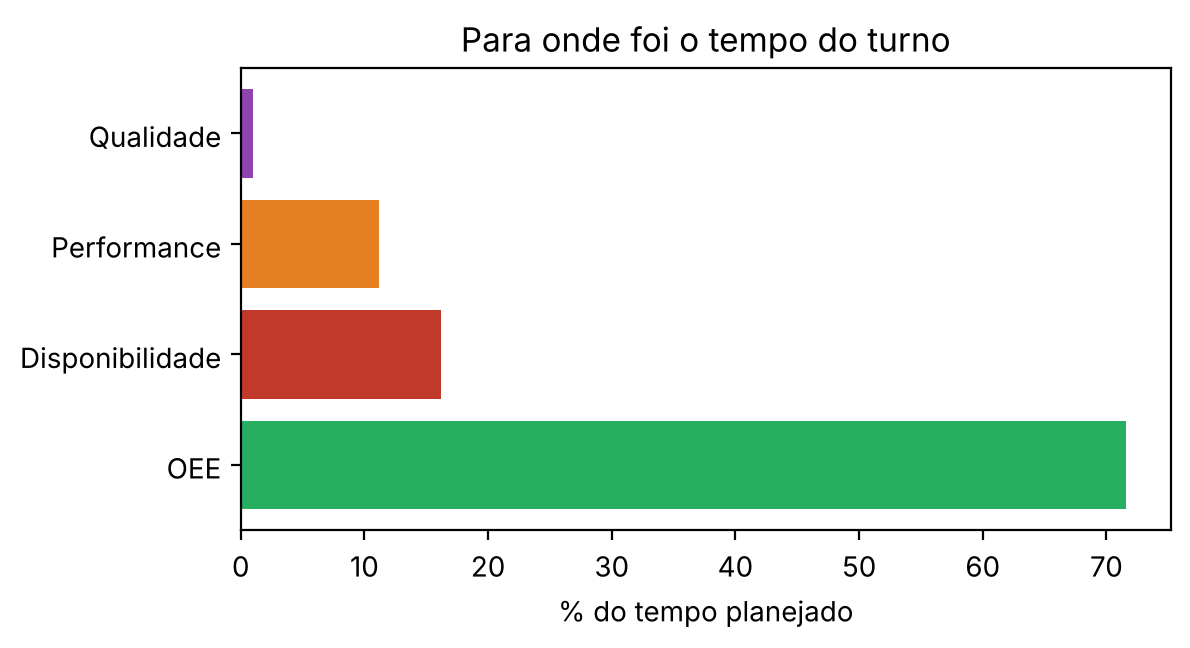

In [8]:
perdas = {"Disponibilidade": 1 - k["availability"],
          "Performance": k["availability"] * (1 - k["performance"]),
          "Qualidade": k["availability"] * k["performance"] * (1 - k["quality"])}
plt.figure(figsize=(6, 3))
plt.barh(["OEE"] + list(perdas), [k["oee"] * 100] + [v * 100 for v in perdas.values()], color=["#27ae60", "#c0392b", "#e67e22", "#8e44ad"])
plt.xlabel("% do tempo planejado"); plt.title("Para onde foi o tempo do turno"); plt.show()

**Interpretação**

* **Disponibilidade** perde pelas paradas do Pareto. O almoço **não** conta, porque é parada planejada: fica fora do tempo planejado.
* **Performance** abaixo de 100 % significa que, rodando, a máquina produziu menos que o ciclo ideal permite (o simulador roda entre 80 e 95 % da velocidade ideal). É a perda mais "invisível": a máquina está verde no Andon e mesmo assim perde produção.
* **Qualidade** perde pelo refugo (cerca de 1,5 %).
* As três perdas, somadas ao OEE, dão 100 % do tempo planejado.

## Resumo

* KPI de chão de fábrica = **eventos bem modelados + SQL**. Sem estado com motivo e contador confiável, não há OEE confiável.
* `LEAD` dá duração de estados; `LAG` dá deltas de contadores.
* Separe parada **planejada** de **não planejada**: é isso que torna a Disponibilidade justa.